Need to find non-unitary gate infidelity method.

In [1]:
import os
import numpy as np
import tensorflow as tf
from scipy.linalg import expm
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from qugradlab.systems.semiconducting.esr import SpinChain
import sys
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig
from pulse_vqe_entanglement.entanglement_measures import (GATE_MEASURES, operator_entanglement)

In [2]:
def _initialise_x0(config: SimulationConfig) -> np.ndarray:
    """Initial control parameters drawn uniformly in [-1, 1]."""
    n = config.n_time_steps * config.n_J_channels
    x0 = config.J_init_scale * np.random.uniform(-1.0, 1.0, size=n) + config.J_init_mean
    return np.clip(x0, -1.0, 1.0)

def convert_dtype(np_array) -> tf.Tensor:
    """Convert numpy array to TensorFlow complex128 tensor."""
    return tf.cast(tf.convert_to_tensor(np_array), dtype=tf.complex128)


def single_qubit_excitation(theta: float) -> np.ndarray:
    """
    Single-qubit rotation gate in the two-spin subspace.

    Rotates the |01⟩ ↔ |10⟩ subspace by angle theta while leaving |00⟩ and
    |11⟩ unchanged. Basis order: [|00⟩, |01⟩, |10⟩, |11⟩].
    """
    return np.array(
        [[1, 0, 0, 0],
         [0, np.cos(theta), -np.sin(theta), 0],
         [0, np.sin(theta),  np.cos(theta), 0],
         [0, 0, 0, 1]],
        dtype=np.complex128,
    )

def _get_unitary_traj(config: SimulationConfig, sys: SpinChain, x: np.ndarray,
                      basis_driven_systems: list | None = None) -> np.ndarray:
    """
    Propagate each basis state and assemble the full unitary trajectory.

    Returns
    -------
    U_traj : ndarray, shape (n_fine + 1, 4, 4)
        Unitary at each fine time step, with U_traj[t, :, i] = U(t)|i⟩.
    """
    x = np.asarray(x, dtype=np.float64)
    n_fine = int(config.n_time_steps) * int(config.n_discretisation)
    U_traj = np.zeros((n_fine + 1, 4, 4), dtype=np.complex128)

    if basis_driven_systems is None:
        basis_driven_systems = _build_basis_driven_systems(config, sys)

    for i, ds in enumerate(basis_driven_systems):
        U_traj[:, :, i] = np.asarray(ds.propagate_all(x)).T

    return U_traj


def gate_infidelity(U: np.ndarray, target: np.ndarray) -> float:
    """Gate infidelity: 1 - (|Tr(U†T)|² + d) / (d(d+1))."""
    d = U.shape[0]
    return float(1.0 - (np.abs(np.trace(target.conj().T @ U)) ** 2 + d) / (d * (d + 1)))


def get_gate_infidelity_traj(U_traj: np.ndarray, target: np.ndarray) -> np.ndarray:
    """Gate infidelity at each time step along U_traj."""
    return np.array([gate_infidelity(U_traj[t], target) for t in range(U_traj.shape[0])])


def get_gate_entanglement_traj(U_traj: np.ndarray,
                               measure_fn=operator_entanglement) -> np.ndarray:
    """
    Gate entanglement measure at each time step along U_traj.

    Parameters
    ----------
    measure_fn : callable
        A gate measure from GATE_MEASURES. Defaults to operator_entanglement.
    """
    return np.array([measure_fn(U_traj[t]) for t in range(U_traj.shape[0])])

def _cost_entangling_power(basis_driven_systems: list, config: SimulationConfig,
                           x: np.ndarray, *, ep_max: float) -> float:
    """
    Mean squared trajectory violation of the entanglement cap.

    cost = mean((E(t) - E_max)₊²), where E is config.gate_ent_measure.
    """
    ent_fn = GATE_MEASURES[config.gate_ent_measure]
    U_traj = _get_unitary_traj(config, None, x, basis_driven_systems=basis_driven_systems)
    viol = np.maximum(0.0, get_gate_entanglement_traj(U_traj, ent_fn) - ep_max)
    return float(np.mean(viol**2))


def _ep_grad_fd(basis_driven_systems: list, config: SimulationConfig, x: np.ndarray, *,
                ep_max: float, eps: float, f0: float | None = None) -> np.ndarray:
    """
    Forward-difference gradient of the entanglement cost, parallelised over parameters.

    Parameters
    ----------
    f0 : float, optional
        Cost at the unperturbed x. Providing it avoids a redundant evaluation.
    """
    x = np.asarray(x, float)
    if f0 is None:
        f0 = _cost_entangling_power(basis_driven_systems, config, x, ep_max=ep_max)

    def _fi(i: int) -> float:
        xp = x.copy()
        xp[i] += eps
        return (_cost_entangling_power(basis_driven_systems, config, xp, ep_max=ep_max) - f0) / eps

    with ThreadPoolExecutor(max_workers=min(len(x), os.cpu_count() or 1)) as pool:
        return np.array(list(pool.map(_fi, range(len(x)))), dtype=float)


def _lagrangian_and_grad(
    driven_sys, basis_driven_systems: list, config: SimulationConfig, x: np.ndarray, *,
    target_gate: np.ndarray, lam: float, ep_max: float, fd_eps: float, rho: float,
    eps_infidelity: float,
) -> tuple[float, np.ndarray]:
    """
    Augmented Lagrangian value and gradient.

    Objective: L = EP_cost + λ(GI - ε) + (ρ/2)(GI - ε)²

    where EP_cost is the mean-squared entanglement violation (using
    config.gate_ent_measure) and GI is the gate infidelity (GI ≤ ε via λ).
    """
    EP = _cost_entangling_power(basis_driven_systems, config, x, ep_max=ep_max)
    gEP = _ep_grad_fd(basis_driven_systems, config, x, ep_max=ep_max, eps=fd_eps, f0=EP)

    gi, ggi = driven_sys.gate_gradient(x, target_gate)
    gi, ggi = float(gi), np.asarray(ggi, float)
    c = gi - float(eps_infidelity)

    L = EP + lam * c + 0.5 * float(rho) * c**2
    gL = gEP + (lam + float(rho) * c) * ggi
    return float(L), gL


def _primal_dual_optimise(
    driven_sys, basis_driven_systems: list, config: SimulationConfig, x0: np.ndarray, *,
    target_gate: np.ndarray, bounds, verbose: bool = True,
) -> tuple[np.ndarray, float, list[dict]]:
    """
    Augmented Lagrangian primal-dual loop.

    Each outer iteration minimises the Lagrangian via L-BFGS-B, then updates
    the dual variable λ ← max(0, λ + α(GI - ε)).

    Returns
    -------
    x_final : np.ndarray
    lam_final : float
    history : list[dict]  – per-outer-iteration diagnostics
    """
    x = np.asarray(x0, float).copy()
    lam = 1.0
    ep_max = float(config.S_max)
    hist: list[dict] = []

    for k in range(int(config.n_outer)):
        res = minimize(
            lambda z: _lagrangian_and_grad(
                driven_sys, basis_driven_systems, config, z,
                target_gate=target_gate, lam=lam, ep_max=ep_max,
                fd_eps=float(config.fd_eps), rho=float(config.rho),
                eps_infidelity=float(config.eps_infidelity),
            ),
            x0=x, jac=True, method="L-BFGS-B", bounds=bounds,
            options={"maxiter": int(config.inner_maxiter), "gtol": float(config.gtol)},
        )
        x = np.asarray(res.x, float)

        gi = float(driven_sys.gate_gradient(x, target_gate)[0])
        c = gi - float(config.eps_infidelity)
        lam = max(0.0, lam + float(config.dual_lr) * c) # Ensures λ ≥ 0
        #lam = lam + float(config.dual_lr) * c

        EP = _cost_entangling_power(basis_driven_systems, config, x, ep_max=ep_max)

        hist.append({
            "outer_iter": k, "lam": lam, "GI_final": gi, "constraint_residual": c,
            "inner_success": bool(res.success), "inner_nit": int(res.nit),
            "inner_fun": float(res.fun),
            "inner_grad_norm": float(np.linalg.norm(res.jac)) if res.jac is not None else np.nan,
            "EP": EP,
            "message": str(res.message),
        })
        if verbose:
            print(f"[outer {k:02d}] GI={gi:.3e}, lam={lam:.6e}, "
                  f"inner_nit={res.nit}, inner_success={res.success}, EP={EP:.3e}")

    return x, lam, hist

def _make_driven_sys(config: SimulationConfig, sys: SpinChain):
    """
    Create a driven system with piecewise-constant pulse interpolation.

    Optimization parameters live on a coarse grid (n_time_steps); state
    evolution uses a finer grid (n_time_steps × n_discretisation) via
    piecewise-constant interpolation.
    """
    n_steps = int(config.n_time_steps)
    n_disc = int(config.n_discretisation)
    n_fine = n_steps * n_disc
    dt_fine_us = (float(config.T) / n_fine) * NS_TO_US

    def pulse_function(x):
        x_coarse = tf.reshape(tf.convert_to_tensor(x, dtype=tf.float64),
                              (n_steps, int(config.n_J_channels)))
        x_fine = tf.cast(tf.repeat(x_coarse, repeats=n_disc, axis=0), tf.complex128)
        return (
            convert_dtype(np.zeros((n_fine, 2))),   # drive amplitudes (disabled)
            tf.zeros(2),                            # drive frequencies
            x_fine,                                 # J coupling amplitudes
            convert_dtype(config.initial_state),    # initial state
            dt_fine_us * 2 * np.pi,                 # timestep (rad/μs)
        )

    return sys.pulse_form(pulse_function)


def _build_basis_driven_systems(config: SimulationConfig, sys: SpinChain) -> list:
    """
    Build one driven system per computational basis state.

    Constructed once before optimisation so TF graph compilation happens only
    once, not on every function evaluation. Each system propagates a single
    basis vector, allowing reconstruction of the full unitary trajectory.
    """
    dim = 4
    systems = []
    for i in range(dim):
        basis = np.zeros(dim, dtype=np.complex128)
        basis[i] = 1.0
        cfg_i = SimulationConfig(**vars(config))
        cfg_i.initial_state = basis
        systems.append(_make_driven_sys(cfg_i, sys))
    return systems

In [3]:
config = SimulationConfig(
    zeeman_splittings=np.array([1000.0, 1008.0]),
    initial_state=np.array([0.0, 1.0, 0.0, 0.0], dtype=np.complex128), # Dummy
    theta_target=0.01 * np.pi,
    n_time_steps=50,
    n_discretisation=1,
    T=500.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e0,
    J_init_mean=0.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    entanglement_optimisation=False,
    gate_ent_measure="average_entangling_power",
    #gate_ent_measure="operator_entanglement",
    #extra_ent_measures=["linear"],
    J_init_seed=None,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-7,
    rho=0.0,
    dual_lr=1e10,
    n_outer=3,
    inner_maxiter=500,
    fd_eps=1e-6,
)

In [4]:
NS_TO_US = 1e-3

I2 = np.eye(2, dtype=np.complex128)
Splus = np.array([[0, 1], [0, 0]], dtype=np.complex128)
Sminus = np.array([[0, 0], [1, 0]], dtype=np.complex128)
X = np.array([[0, 1], [1, 0]], dtype=np.complex128)
Y = np.array([[0, -1j], [1j, 0]], dtype=np.complex128)
Z = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=np.complex128)
Z1 = np.kron(Z, I2)
Z2 = np.kron(I2, Z)

B = np.array(config.zeeman_splittings, dtype=np.float64)
B_avg = np.mean(B)
deltaB = B - B_avg
U_rot = expm(-1j * np.pi 
                * (deltaB[0] * Z1 + deltaB[1] * Z2) 
                * config.T * NS_TO_US)

target_gate = U_rot @ single_qubit_excitation(config.theta_target)
target_state = target_gate @ config.initial_state

sys = SpinChain(
    spins=2,
    zeeman_splittings=deltaB,
    max_drive_strength=config.max_drive_strength,
    J_max=config.J_max,
    J_min=config.J_min,
    feromagnetic=config.feromagnetic,
    use_graph=True,
)

n_steps = config.n_time_steps
n_disc = config.n_discretisation
n_fine = n_steps * n_disc
dt_fine_us = (config.T / n_fine) * NS_TO_US

def pulse_function(x):
    x_coarse = tf.reshape(convert_dtype(x), (n_steps, config.n_J_channels))
    x_fine = tf.repeat(x_coarse, repeats=n_disc, axis=0)
    return (
        convert_dtype(np.zeros((n_fine, 2))),       # drive amplitudes (disabled)
        convert_dtype(config.zeeman_splittings),    # drive frequencies
        x_fine,                                     # J coupling amplitudes
        convert_dtype(config.initial_state),        # initial state
        dt_fine_us * 2 * np.pi,                     # timestep (rad/μs)
    )

driven_sys = sys.pulse_form(pulse_function)

x0 = _initialise_x0(config)
bounds = [(-1.0, 1.0)] * len(x0)

In [5]:
res = minimize(
    driven_sys.gate_gradient, x0, args=(target_gate,),
    jac=True, bounds=bounds, method="L-BFGS-B",
    options={"maxiter": int(config.maxiter), "gtol": float(config.gtol)},
)

basis_driven_systems = _build_basis_driven_systems(config, sys)

gn = float(np.linalg.norm(res.jac)) if res.jac is not None else 0.0
EP = _cost_entangling_power(basis_driven_systems, config, res.x, ep_max=float(config.S_max))
xf = res.x
print(f"Infidelity: I={res.fun:.3e}, nit={res.nit}, success={res.success}, grad_norm={gn:.3e}, EP={EP:.3e}")

Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Infidelity: I=1.206e-13, nit=18, success=True, grad_norm=1.771e-07, EP=1.433e-01


In [6]:
xf_ent, lam, hist = _primal_dual_optimise(
            driven_sys, basis_driven_systems, config, x0,
            target_gate=target_gate, bounds=bounds, verbose=True,
        )
print(lam)

[outer 00] GI=6.564e-01, lam=6.563815e+09, inner_nit=2, inner_success=True, EP=1.513e-01
[outer 01] GI=3.245e-12, lam=6.563814e+09, inner_nit=21, inner_success=True, EP=1.368e-01
[outer 02] GI=2.827e-12, lam=6.563813e+09, inner_nit=6, inner_success=True, EP=1.435e-01
6563812787.668891


In [7]:
infidelity_xf = np.abs(driven_sys.evolved_gate_infidelity(xf, target_gate))
infidelity_xf_ent = np.abs(driven_sys.evolved_gate_infidelity(xf_ent, target_gate))
print(f"Infidelity (unconstrained): {infidelity_xf:.3e}")
print(f"Infidelity (entanglement-constrained): {infidelity_xf_ent:.3e}")

Infidelity (unconstrained): 1.206e-13
Infidelity (entanglement-constrained): 2.827e-12


In [8]:
def local_depolarising_ops_2q(gamma):

    return np.array([
        np.sqrt(gamma/4) * np.kron(X, I2),
        np.sqrt(gamma/4) * np.kron(Y, I2),
        np.sqrt(gamma/4) * np.kron(Z, I2),
        np.sqrt(gamma/4) * np.kron(I2, X),
        np.sqrt(gamma/4) * np.kron(I2, Y),
        np.sqrt(gamma/4) * np.kron(I2, Z),
    ], dtype=np.complex128)

L0 = local_depolarising_ops_2q(1e-5)

sys_noisy = sys.add_lindblad_terms(L0=L0)

def Lindblad_pulse_function(x):
    x_coarse = tf.reshape(convert_dtype(x), (n_steps, config.n_J_channels))
    x_fine = tf.repeat(x_coarse, repeats=n_disc, axis=0)
    psi0 = config.initial_state
    return (
        convert_dtype(np.zeros((n_fine, 2))),       # drive amplitudes (disabled)
        convert_dtype(config.zeeman_splittings),    # drive frequencies
        convert_dtype(x_fine),                      # J coupling amplitudes
        convert_dtype(np.outer(psi0, psi0.conj())), # initial state (density matrix)
        convert_dtype(dt_fine_us * 2 * np.pi),      # timestep (rad/μs)
    )

driven_sys_noisy = sys_noisy.pulse_form(Lindblad_pulse_function)

cptp_xf = driven_sys_noisy.get_evolution(xf)
cptp_xf_ent = driven_sys_noisy.get_evolution(xf_ent)

target_cptp = np.kron(target_gate, target_gate.conj())

infidelity_xf_noisy = gate_infidelity(cptp_xf, target_cptp)
infidelity_xf_ent_noisy = gate_infidelity(cptp_xf_ent, target_cptp)

print(f"Infidelity with noise (unconstrained): {infidelity_xf_noisy:.3e}")
print(f"Infidelity with noise (entanglement-constrained): {infidelity_xf_ent_noisy:.3e}")

Tracing control amplitude graph.
Infidelity with noise (unconstrained): 8.870e-05
Infidelity with noise (entanglement-constrained): 8.870e-05


Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.


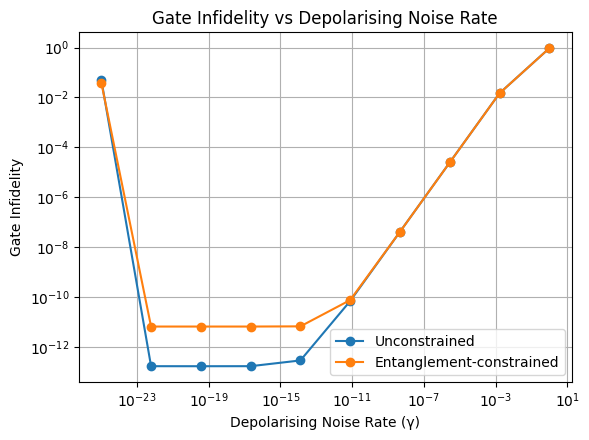

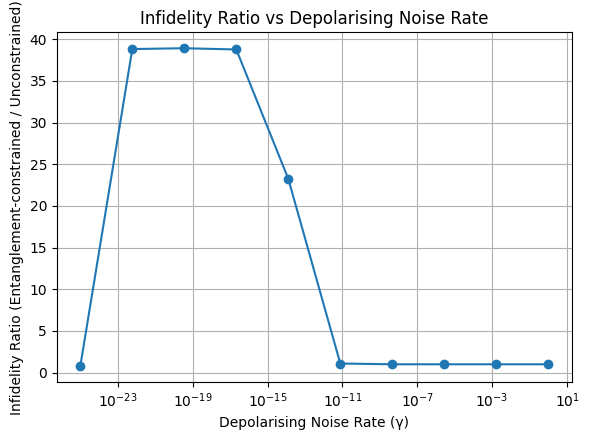

In [9]:
# Plot infidelities and their ratio against depolarising noise rate

noise_rates = np.logspace(-25, 0, num=10)
infidelities_xf = []
infidelities_xf_ent = []
infidelity_ratios = []

for gamma in noise_rates:
    L0 = local_depolarising_ops_2q(gamma)
    sys_noisy = sys.add_lindblad_terms(L0=L0)
    driven_sys_noisy = sys_noisy.pulse_form(Lindblad_pulse_function)

    cptp_xf = driven_sys_noisy.get_evolution(xf)
    cptp_xf_ent = driven_sys_noisy.get_evolution(xf_ent)

    infidelity_xf_noisy = gate_infidelity(cptp_xf, target_cptp)
    infidelity_xf_ent_noisy = gate_infidelity(cptp_xf_ent, target_cptp)
    infidelity_ratios.append(infidelity_xf_ent_noisy / infidelity_xf_noisy)

    infidelities_xf.append(infidelity_xf_noisy)
    infidelities_xf_ent.append(infidelity_xf_ent_noisy)

plt.figure(figsize=(6, 4.5))
plt.loglog(noise_rates, infidelities_xf, marker='o', label='Unconstrained')
plt.loglog(noise_rates, infidelities_xf_ent, marker='o', label='Entanglement-constrained')
plt.xlabel('Depolarising Noise Rate (γ)')
plt.ylabel('Gate Infidelity')
plt.title('Gate Infidelity vs Depolarising Noise Rate')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4.5))
plt.semilogx(noise_rates, infidelity_ratios, marker='o')
plt.xlabel('Depolarising Noise Rate (γ)')
plt.ylabel('Infidelity Ratio (Entanglement-constrained / Unconstrained)')
plt.title('Infidelity Ratio vs Depolarising Noise Rate')
plt.grid()
plt.tight_layout()
plt.show()

Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.


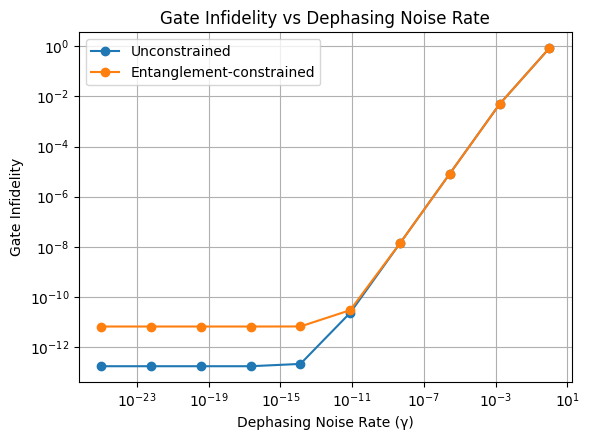

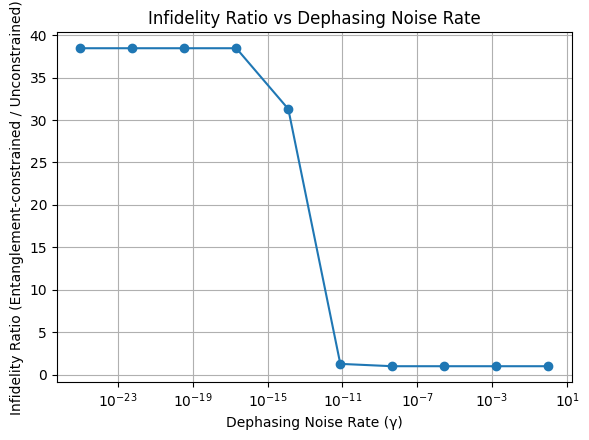

In [10]:
# Plot for dephasing noise

def local_dephasing_ops_2q(gamma):
    return np.array([
        np.sqrt(gamma/4) * np.kron(Z, I2),
        np.sqrt(gamma/4) * np.kron(I2, Z),
    ], dtype=np.complex128) 

noise_rates = np.logspace(-25, 0, num=10)
infidelities_xf = []
infidelities_xf_ent = []
infidelity_ratios = []

for gamma in noise_rates:
    L0 = local_dephasing_ops_2q(gamma)
    sys_noisy = sys.add_lindblad_terms(L0=L0)
    driven_sys_noisy = sys_noisy.pulse_form(Lindblad_pulse_function)

    cptp_xf = driven_sys_noisy.get_evolution(xf)
    cptp_xf_ent = driven_sys_noisy.get_evolution(xf_ent)

    infidelity_xf_noisy = gate_infidelity(cptp_xf, target_cptp)
    infidelity_xf_ent_noisy = gate_infidelity(cptp_xf_ent, target_cptp)
    infidelity_ratios.append(infidelity_xf_ent_noisy / infidelity_xf_noisy)

    infidelities_xf.append(infidelity_xf_noisy)
    infidelities_xf_ent.append(infidelity_xf_ent_noisy)

plt.figure(figsize=(6, 4.5))
plt.loglog(noise_rates, infidelities_xf, marker='o', label='Unconstrained')
plt.loglog(noise_rates, infidelities_xf_ent, marker='o', label='Entanglement-constrained')
plt.xlabel('Dephasing Noise Rate (γ)')
plt.ylabel('Gate Infidelity')
plt.title('Gate Infidelity vs Dephasing Noise Rate')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4.5))
plt.semilogx(noise_rates, infidelity_ratios, marker='o')
plt.xlabel('Dephasing Noise Rate (γ)')
plt.ylabel('Infidelity Ratio (Entanglement-constrained / Unconstrained)')
plt.title('Infidelity Ratio vs Dephasing Noise Rate')
plt.grid()
plt.tight_layout()
plt.show()

Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.


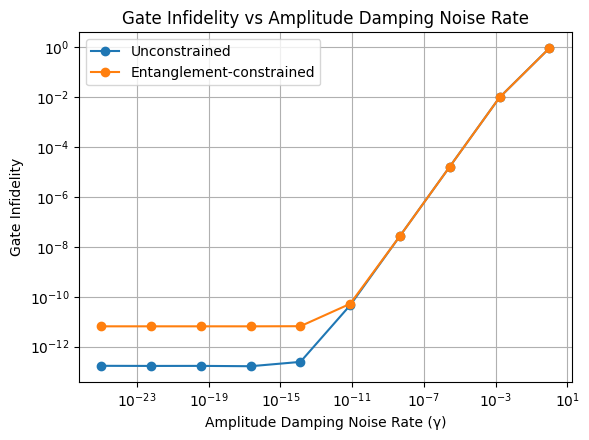

In [11]:
# Plot for amplitude damping noise

def local_amplitude_damping_ops_2q(gamma):
    return np.array([
        np.sqrt(gamma) * np.kron(Sminus, I2),
        np.sqrt(gamma) * np.kron(I2, Sminus),
    ], dtype=np.complex128)

noise_rates = np.logspace(-25, 0, num=10)
infidelities_xf = []
infidelities_xf_ent = []
infidelity_ratios = []  

for gamma in noise_rates:
    L0 = local_amplitude_damping_ops_2q(gamma)
    sys_noisy = sys.add_lindblad_terms(L0=L0)
    driven_sys_noisy = sys_noisy.pulse_form(Lindblad_pulse_function)

    cptp_xf = driven_sys_noisy.get_evolution(xf)
    cptp_xf_ent = driven_sys_noisy.get_evolution(xf_ent)

    infidelity_xf_noisy = gate_infidelity(cptp_xf, target_cptp)
    infidelity_xf_ent_noisy = gate_infidelity(cptp_xf_ent, target_cptp)
    infidelity_ratios.append(infidelity_xf_ent_noisy / infidelity_xf_noisy)

    infidelities_xf.append(infidelity_xf_noisy)
    infidelities_xf_ent.append(infidelity_xf_ent_noisy)

plt.figure(figsize=(6, 4.5))
plt.loglog(noise_rates, infidelities_xf, marker='o', label='Unconstrained')
plt.loglog(noise_rates, infidelities_xf_ent, marker='o', label='Entanglement-constrained')
plt.xlabel('Amplitude Damping Noise Rate (γ)')
plt.ylabel('Gate Infidelity')
plt.title('Gate Infidelity vs Amplitude Damping Noise Rate')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()